# FedAvg Baseline — Federated Fraud Detection on IEEE-CIS

**Project:** AQ-FL (Adversarial Post-Quantum Federated Learning) — fraud detection across 10 simulated financial-institution clients.

**Purpose.** Establish the *federated baseline* that the AQ-FL secure-aggregation layers are later measured against. This notebook trains a PyTorch MLP under **real Flower** (`flwr.simulation.run_simulation`, Ray backend) with the stock `FedAvg` strategy — no hand-rolled round loop — and compares it against a centralised upper bound.

**Relationship to the audit notebooks.** `ieee_cis_audit_eda.ipynb` characterised the data and fixed the partitioning protocol; this notebook consumes that protocol unchanged (`dirichlet_partition` is copied verbatim from its Section 7).

**Conditions.**

| Condition | Description |
|---|---|
| Centralised | Same architecture, pooled 80% training portion, single trainer — the upper bound |
| FedAvg $\alpha = 100$ | IID-like baseline partition across 10 clients |
| FedAvg $\alpha = 1.0$ | Primary non-IID condition, calibrated to the measured `ProductCD` split |

$\alpha = 0.5$ is deliberately **not** run here: the audit retains it as a stress case for probing Byzantine-filter breaking behaviour, not as a training condition.

> **Kernel.** This notebook requires the `AQ-FL` conda environment (Python 3.13 + torch + flwr + ray). Ray does not install under the project's Python 3.14 `.venv`, so that environment cannot run this notebook.

**Contents**
0. Environment, device, and run configuration
1. Load, join, and preprocess
2. Temporal split
3. Dirichlet partitioning
4. Model definition
5. Flower client
6. Centralised reference (upper bound)
7. Federated simulations
8. Results — summary table and convergence chart
9. Known simplifications

## 0. Environment, device, and run configuration

In [1]:
# Installed once into the AQ-FL conda environment. Left here for reproducibility.
# %pip install -q torch "flwr[simulation]" scikit-learn pandas matplotlib seaborn

In [2]:
import gc
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

import flwr
import ray
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from flwr.client import ClientApp, NumPyClient
from flwr.common import Context, ndarrays_to_parameters
from flwr.server import ServerApp, ServerAppComponents, ServerConfig
from flwr.server.strategy import FedAvg
from flwr.simulation import run_simulation

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")
pd.set_option("display.max_columns", 120)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"torch        {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}  ->  device: {DEVICE}")
print(f"flwr         {flwr.__version__}")
print(f"ray          {ray.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"numpy {np.__version__} | pandas {pd.__version__}")
print(f"logical CPUs: {os.cpu_count()}")

torch        2.15.0+cpu
CUDA available: False  ->  device: cpu
flwr         1.39.0
ray          2.59.0
scikit-learn 1.9.1
numpy 2.5.3 | pandas 3.0.6
logical CPUs: 24


**Simulation backend.** `flwr[simulation]` pins `ray==2.55.1`, whose dependency marker excludes Windows on Python ≥ 3.13; the `AQ-FL` conda environment already carries a working `ray`, so the **real Ray-backed `run_simulation` path is used** — not a manual fallback. Flower 1.39 exposes the `ServerApp`/`ClientApp` API, so `run_simulation` is the correct entry point (the older `start_simulation` is the deprecated shim).

In [3]:
SEED = 42
N_CLIENTS = 10
ALPHAS = [100.0, 1.0]          # alpha = 0.5 is the audit's stress case, not a training condition

BATCH_SIZE = 1024
LOCAL_EPOCHS = 1               # per client per round
LR = 1e-3
DROPOUT = 0.3
CPUS_PER_CLIENT = 2            # 10 clients x 2 = 20 of 24 logical cores
PRINT_EVERY = 5                # log cadence; first and final round always print

# ---- configuration ACTUALLY EXECUTED in this saved run -------------------
SAMPLE_FRAC = 1.0
NUM_ROUNDS = 30
# ---- smoke-test configuration (run first, passed: ordering held at
#      centralised 0.9009 > alpha=100 0.8627 > alpha=1.0 0.8558) -----------
# SAMPLE_FRAC = 0.05
# NUM_ROUNDS = 3
# --------------------------------------------------------------------------

np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = (Path("..") / "Data" / "IEEE-CIS_Fraud_Detection").resolve()
SHARD_DIR = (Path("..") / "Data" / "derived" / "fl_shards").resolve()
SHARD_DIR.mkdir(parents=True, exist_ok=True)

print(f"SAMPLE_FRAC={SAMPLE_FRAC} | NUM_ROUNDS={NUM_ROUNDS} | N_CLIENTS={N_CLIENTS} | alphas={ALPHAS}")
print(f"shards -> {SHARD_DIR}")

SAMPLE_FRAC=1.0 | NUM_ROUNDS=30 | N_CLIENTS=10 | alphas=[100.0, 1.0]
shards -> D:\AQ-FL-Repo\Data\derived\fl_shards


## 1. Load, join, and preprocess

The join logic matches `ieee_cis_audit_eda.ipynb` Section 1: a left join of `train_transaction` onto `train_identity` on `TransactionID`, preserving all transactions.

In [4]:
t0 = time.time()
txn = pd.read_csv(DATA_DIR / "train_transaction.csv")
idn = pd.read_csv(DATA_DIR / "train_identity.csv")
df = txn.merge(idn, on="TransactionID", how="left")
del txn, idn
gc.collect()
print(f"joined: {df.shape[0]:,} rows x {df.shape[1]} columns  ({time.time() - t0:.0f}s)")

joined: 590,540 rows x 434 columns  (12s)


In [5]:
# Temporal ordering is fixed BEFORE any sampling so the holdout is always the latest slice.
df = df.sort_values("TransactionDT").reset_index(drop=True)

if SAMPLE_FRAC < 1.0:
    n_keep = int(len(df) * SAMPLE_FRAC)
    df = df.iloc[:n_keep].copy()   # contiguous earliest window keeps the time axis intact
    gc.collect()
    print(f"SAMPLE_FRAC={SAMPLE_FRAC} -> {len(df):,} rows retained")

y_all = df["isFraud"].to_numpy(dtype=np.float32)
# TransactionDT is dropped as a FEATURE: it orders the split, so keeping it would let the
# model read its own position relative to the train/test cutoff.
feature_df = df.drop(columns=["isFraud", "TransactionID", "TransactionDT"])
del df                              # released here: the full run peaks near the RAM budget
gc.collect()
print(f"raw feature columns: {feature_df.shape[1]}")

raw feature columns: 431


> **Global preprocessing — a deliberate, flagged simplification.** The scaler, imputers, and one-hot encoder below are fit on the **pooled** 80% training portion, then applied to every client. In a genuine federated deployment this is not permissible: it presumes a central party has already seen all clients' feature distributions, which is precisely the data-sharing step federated learning exists to avoid.
>
> It is accepted here because the quantity this baseline must measure is the **cost of heterogeneity under FedAvg**. Per-client preprocessing would make each client's feature space slightly different, adding a second source of variance that is confounded with the partition skew under study. Fixing preprocessing globally isolates the partitioning effect. Federated or per-client preprocessing is deferred to the AQ-FL implementation, where it is recorded as a known gap (Section 9).

In [6]:
split_at = int(len(feature_df) * 0.8)

# Everything non-numeric is categorical. Selecting the complement avoids pandas 3's
# object/str dtype ambiguity, which makes include=["object"] both warn and under-select.
num_cols = feature_df.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in feature_df.columns if c not in set(num_cols)]
print(f"numeric columns: {len(num_cols)} | categorical columns: {len(cat_cols)}")

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
# min_frequency collapses the long tail (e.g. ~1,800 distinct DeviceInfo strings) into an
# 'infrequent' bucket, keeping the one-hot width tractable for an MLP.
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="__missing__")),
    ("onehot", OneHotEncoder(min_frequency=0.005, handle_unknown="infrequent_if_exist",
                             sparse_output=False, dtype=np.float32)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

numeric columns: 400 | categorical columns: 31


In [7]:
t0 = time.time()
# Fit on the TRAINING portion only (constraint 4): the holdout must stay unseen.
preprocessor.fit(feature_df.iloc[:split_at])

X_train = preprocessor.transform(feature_df.iloc[:split_at]).astype(np.float32)
X_test = preprocessor.transform(feature_df.iloc[split_at:]).astype(np.float32)
y_train = y_all[:split_at]
y_test = y_all[split_at:]

del feature_df
gc.collect()

INPUT_DIM = X_train.shape[1]
print(f"preprocessing done in {time.time() - t0:.0f}s")
print(f"X_train {X_train.shape} | X_test {X_test.shape} | dtype {X_train.dtype}")
print(f"\n>>> INPUT_DIM after preprocessing: {INPUT_DIM}")

preprocessing done in 51s
X_train (472432, 542) | X_test (118108, 542) | dtype float32

>>> INPUT_DIM after preprocessing: 542


In [8]:
n_num = len(num_cols)
n_cat_expanded = INPUT_DIM - n_num
print(f"  numeric passthrough      : {n_num}")
print(f"  one-hot expanded from {len(cat_cols):>2} categoricals: {n_cat_expanded}")
print(f"  total input_dim          : {INPUT_DIM}")
print(f"\nDissertation currently states input_dim = 434.")
print(f"434 is the raw joined COLUMN COUNT (394 + 41 - 1 shared key), not the model input width.")
print(f"After dropping isFraud/TransactionID/TransactionDT and one-hot encoding, "
      f"the true input_dim is {INPUT_DIM}.")

  numeric passthrough      : 400
  one-hot expanded from 31 categoricals: 142
  total input_dim          : 542

Dissertation currently states input_dim = 434.
434 is the raw joined COLUMN COUNT (394 + 41 - 1 shared key), not the model input width.
After dropping isFraud/TransactionID/TransactionDT and one-hot encoding, the true input_dim is 542.


## 2. Temporal split

The last 20% of transactions by `TransactionDT` form the global held-out test set. Every condition — centralised and federated — is scored on this same holdout, so the numbers in Section 8 are directly comparable. A temporal rather than random split matches deployment: a fraud model is always applied to transactions later than those it was trained on.

In [9]:
rows = pd.DataFrame({
    "split": ["train (first 80%)", "test (last 20%)"],
    "rows": [len(y_train), len(y_test)],
    "fraud_count": [int(y_train.sum()), int(y_test.sum())],
    "fraud_rate_pct": [round(float(y_train.mean()) * 100, 3), round(float(y_test.mean()) * 100, 3)],
})
rows

,split,rows,fraud_count,fraud_rate_pct
0,train (first 80%),472432,16599,3.514
1,test (last 20%),118108,4064,3.441


In [10]:
POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"pos_weight (neg/pos on the training portion): {POS_WEIGHT:.2f}")

pos_weight (neg/pos on the training portion): 27.46


The fraud rate differs between the two slices — fraud prevalence drifts over the ~6-month window. This is a property of the data, not a split defect, and it is the realistic condition a deployed model faces.

## 3. Dirichlet partitioning

`dirichlet_partition` is copied **verbatim** from `ieee_cis_audit_eda.ipynb` Section 7 (Hsu et al., 2019, arXiv:1909.06335). Only the 80% training portion is partitioned; the holdout stays global.

In [11]:
def dirichlet_partition(labels, n_clients, alpha, rng):
    assignment = np.empty(len(labels), dtype=int)
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        props = rng.dirichlet(np.full(n_clients, alpha))
        cuts = (np.cumsum(props[:-1]) * len(idx)).astype(int)
        for k, part in enumerate(np.split(idx, cuts)):
            assignment[part] = k
    return assignment


def client_stats(labels, assignment):
    stats = (pd.DataFrame({"client": assignment, "label": labels})
             .groupby("client")["label"]
             .agg(rows="size", fraud_count="sum", fraud_rate="mean"))
    stats["fraud_rate_pct"] = (stats["fraud_rate"] * 100).round(3)
    return stats

In [12]:
rng = np.random.default_rng(SEED)
assignments, partition_tables = {}, {}
for a in ALPHAS:
    assignments[a] = dirichlet_partition(y_train, N_CLIENTS, a, rng)
    partition_tables[a] = client_stats(y_train, assignments[a])

for a in ALPHAS:
    print(f"--- alpha = {a} | per-client fraud-rate std: "
          f"{partition_tables[a]['fraud_rate'].std():.5f} ---")
    print(partition_tables[a].to_string(), "\n")

--- alpha = 100.0 | per-client fraud-rate std: 0.00293 ---
         rows  fraud_count  fraud_rate  fraud_rate_pct
client                                                
0       38439       1435.0    0.037332           3.733
1       42794       1591.0    0.037178           3.718
2       49992       1729.0    0.034586           3.459
3       42027       1673.0    0.039808           3.981
4       55428       1940.0    0.035000           3.500
5       54591       1923.0    0.035226           3.523
6       44448       1613.0    0.036290           3.629
7       49763       1417.0    0.028475           2.847
8       51540       1767.0    0.034284           3.428
9       43410       1511.0    0.034808           3.481 

--- alpha = 1.0 | per-client fraud-rate std: 0.04494 ---
          rows  fraud_count  fraud_rate  fraud_rate_pct
client                                                 
0        38663       1261.0    0.032615           3.262
1       119791        422.0    0.003523           0.35

Compare against the audit's full-table sweep ($\alpha = 100$ → std 0.0061, $\alpha = 1.0$ → std 0.0274, measured natural `ProductCD` split → 0.0399). Exact agreement is not expected: the audit partitioned all 590K rows, whereas this partitions only the 80% training slice, so the draws differ. The relative ordering — $\alpha = 100$ an order of magnitude more homogeneous than $\alpha = 1.0$, with $\alpha = 1.0$ sitting near the natural split — is what must hold.

In [13]:
# One memmap-able copy of the training matrix plus tiny per-client index files.
# Ray runs each ClientApp in a separate process, so clients cannot read notebook globals;
# they slice their own rows out of the memmap instead of each holding a full copy.
X_TRAIN_PATH = SHARD_DIR / "X_train.npy"
Y_TRAIN_PATH = SHARD_DIR / "y_train.npy"
np.save(X_TRAIN_PATH, X_train)
np.save(Y_TRAIN_PATH, y_train)

for a in ALPHAS:
    for k in range(N_CLIENTS):
        idx = np.where(assignments[a] == k)[0]
        idx.sort()                      # sorted indices keep the memmap read sequential
        np.save(SHARD_DIR / f"idx_alpha{a}_client{k}.npy", idx)

print(f"X_train.npy: {X_TRAIN_PATH.stat().st_size / 2**20:,.0f} MiB")
print(f"index files: {len(ALPHAS) * N_CLIENTS}")

del X_train
gc.collect()
print("training matrix released from notebook memory (clients read it via memmap)")

X_train.npy: 977 MiB
index files: 20
training matrix released from notebook memory (clients read it via memmap)


## 4. Model

A fully connected MLP, `input_dim -> 448 -> 448 -> 256 -> 1`, ReLU activations, dropout 0.3, trained with `BCEWithLogitsLoss` weighted by `pos_weight` to counteract the ~3.5% class imbalance (the audit's Section 3 conclusion). The single logit output is converted to a probability only at scoring time.

In [14]:
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    accuracy_score, f1_score, precision_score, recall_score,
)


class FraudMLP(nn.Module):
    def __init__(self, input_dim, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 448), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(448, 448), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(448, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)

In [15]:
# Flower exchanges plain ndarrays; these convert to and from the torch state dict.
def get_parameters(model):
    return [v.detach().cpu().numpy() for v in model.state_dict().values()]


def set_parameters(model, parameters):
    state = model.state_dict()
    for key, value in zip(state.keys(), parameters):
        state[key] = torch.tensor(value)
    model.load_state_dict(state)

In [16]:
def train_epochs(model, X, y, epochs, device, pos_weight, batch_size=BATCH_SIZE, lr=LR):
    model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=device))
    n = len(X)
    gen = torch.Generator().manual_seed(SEED)
    for _ in range(epochs):
        order = torch.randperm(n, generator=gen)
        for start in range(0, n, batch_size):
            sel = order[start:start + batch_size]
            xb = torch.from_numpy(X[sel.numpy()]).to(device)
            yb = torch.from_numpy(y[sel.numpy()]).unsqueeze(1).to(device)
            opt.zero_grad()
            loss = lossf(model(xb), yb)
            loss.backward()
            opt.step()
    return model


@torch.no_grad()
def predict_scores(model, X, device, batch_size=8192):
    model.to(device).eval()
    out = np.empty(len(X), dtype=np.float32)
    for start in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[start:start + batch_size]).to(device)
        out[start:start + batch_size] = torch.sigmoid(model(xb)).squeeze(1).cpu().numpy()
    return out

In [17]:
METRIC_KEYS = ["auc_roc", "auc_pr", "accuracy", "f1", "precision", "recall"]


def score(model, X, y, device, threshold=0.5):
    p = predict_scores(model, X, device)
    pred = (p >= threshold).astype(np.float32)
    return {
        "auc_roc": float(roc_auc_score(y, p)),
        "auc_pr": float(average_precision_score(y, p)),
        "accuracy": float(accuracy_score(y, pred)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
    }


def format_metrics(m):
    return (f"AUC-ROC {m['auc_roc']:.4f}  AUC-PR {m['auc_pr']:.4f}  "
            f"Acc {m['accuracy']:.4f}  F1 {m['f1']:.4f}  "
            f"Prec {m['precision']:.4f}  Rec {m['recall']:.4f}")


def should_log(step, total, every=PRINT_EVERY):
    return step == 1 or step == total or step % every == 0

In [18]:
print(f"FraudMLP input_dim = {INPUT_DIM}")
print(FraudMLP(INPUT_DIM))
print(f"trainable parameters: {sum(p.numel() for p in FraudMLP(INPUT_DIM).parameters()):,}")

FraudMLP input_dim = 542
FraudMLP(
  (net): Sequential(
    (0): Linear(in_features=542, out_features=448, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=448, out_features=448, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=448, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, out_features=1, bias=True)
  )
)
trainable parameters: 559,617


## 5. Flower client

A standard `NumPyClient`. Each client loads only its own row indices from the shared memmap, so ten concurrent Ray actors never hold ten copies of the training matrix.

`fraction_evaluate` is set to `0.0` in the strategy below: per-client `evaluate` is implemented as the interface requires, but the measurement that matters is the **centralised** `evaluate_fn`, which scores the aggregated global model on the common holdout after every round. Running both would roughly double simulation time for a number that is not used in Section 8.

In [19]:
_SHARD_CACHE = {}


def load_client_shard(shard_dir, alpha, cid):
    key = (alpha, cid)
    if key not in _SHARD_CACHE:
        idx = np.load(Path(shard_dir) / f"idx_alpha{alpha}_client{cid}.npy")
        X = np.load(Path(shard_dir) / "X_train.npy", mmap_mode="r")[idx]
        y = np.load(Path(shard_dir) / "y_train.npy", mmap_mode="r")[idx]
        _SHARD_CACHE[key] = (np.ascontiguousarray(X), np.ascontiguousarray(y))
    return _SHARD_CACHE[key]


class FlowerClient(NumPyClient):
    def __init__(self, cid, alpha, shard_dir, input_dim, pos_weight):
        torch.set_num_threads(CPUS_PER_CLIENT)
        self.cid = cid
        self.device = torch.device("cpu")
        self.model = FraudMLP(input_dim)
        self.pos_weight = pos_weight
        self.X, self.y = load_client_shard(shard_dir, alpha, cid)

    def get_parameters(self, config):
        return get_parameters(self.model)

    def fit(self, parameters, config):
        set_parameters(self.model, parameters)
        if len(self.X) == 0:
            return get_parameters(self.model), 0, {}
        train_epochs(self.model, self.X, self.y, LOCAL_EPOCHS, self.device, self.pos_weight)
        return get_parameters(self.model), len(self.X), {}

    def evaluate(self, parameters, config):
        set_parameters(self.model, parameters)
        if len(self.X) == 0 or len(np.unique(self.y)) < 2:
            return 0.0, len(self.X), {k: float("nan") for k in METRIC_KEYS}
        return 0.0, len(self.X), score(self.model, self.X, self.y, self.device)


def make_client_fn(alpha, shard_dir, input_dim, pos_weight):
    def client_fn(context: Context):
        cid = int(context.node_config["partition-id"])
        return FlowerClient(cid, alpha, shard_dir, input_dim, pos_weight).to_client()
    return client_fn

> **TODO (AQ-FL).** The secure-aggregation and Byzantine-resilience layers replace the *strategy*, not the client: subclass `flwr.server.strategy.Strategy` (or `FedAvg`) and override `aggregate_fit` to apply secret-shared filtering and the post-quantum verification step before averaging. Flower already ships `Krum` and `Bulyan` as robust-aggregation reference points to benchmark that custom strategy against. Not implemented here — this notebook is the unprotected baseline those layers are measured against.

## 6. Centralised reference (upper bound)

One trainer, the pooled 80% training portion, same architecture and same optimiser. Because all ten clients participate in every FedAvg round and each runs one local epoch, `NUM_ROUNDS` federated rounds consume the same number of passes over the data as `NUM_ROUNDS` centralised epochs — so the two curves are directly comparable round-for-epoch.

In [20]:
t0 = time.time()
X_train_mm = np.load(X_TRAIN_PATH, mmap_mode="r")
X_train_full = np.ascontiguousarray(X_train_mm)
y_train_full = np.load(Y_TRAIN_PATH)

torch.manual_seed(SEED)
central_model = FraudMLP(INPUT_DIM)
central_history = []

for epoch in range(1, NUM_ROUNDS + 1):
    train_epochs(central_model, X_train_full, y_train_full, 1, DEVICE, POS_WEIGHT)
    m = score(central_model, X_test, y_test, DEVICE)
    central_history.append({"round": epoch, **m})
    if should_log(epoch, NUM_ROUNDS):
        print(f"  epoch {epoch:>2}  {format_metrics(m)}")

del X_train_full, y_train_full, X_train_mm
gc.collect()
print(f"\ncentralised reference trained in {time.time() - t0:.0f}s "
      f"(every epoch recorded; logged every {PRINT_EVERY})")

  epoch  1  AUC-ROC 0.8522  AUC-PR 0.3221  Acc 0.8369  F1 0.2287  Prec 0.1366  Rec 0.7028
  epoch  5  AUC-ROC 0.8540  AUC-PR 0.4467  Acc 0.8651  F1 0.2614  Prec 0.1611  Rec 0.6941
  epoch 10  AUC-ROC 0.8550  AUC-PR 0.4139  Acc 0.8907  F1 0.3008  Prec 0.1929  Rec 0.6831
  epoch 15  AUC-ROC 0.8592  AUC-PR 0.4365  Acc 0.8941  F1 0.3002  Prec 0.1943  Rec 0.6599
  epoch 20  AUC-ROC 0.8385  AUC-PR 0.2342  Acc 0.8958  F1 0.2971  Prec 0.1935  Rec 0.6400
  epoch 25  AUC-ROC 0.8569  AUC-PR 0.3914  Acc 0.9155  F1 0.3371  Prec 0.2309  Rec 0.6245
  epoch 30  AUC-ROC 0.8533  AUC-PR 0.3840  Acc 0.9186  F1 0.3414  Prec 0.2366  Rec 0.6132

centralised reference trained in 275s (every epoch recorded; logged every 5)


## 7. Federated simulations

`run_simulation` with a `FedAvg` strategy. The strategy's `evaluate_fn` scores the aggregated global model on the held-out test set after every round, producing the convergence history plotted in Section 8. All ten clients are sampled every round (`fraction_fit = 1.0`), so differences between conditions come from the partition alone.

In [21]:
def make_server_fn(alpha, history_sink, initial_ndarrays, num_rounds):
    def evaluate_fn(server_round, parameters, config):
        model = FraudMLP(INPUT_DIM)
        set_parameters(model, parameters)
        m = score(model, X_test, y_test, DEVICE)
        history_sink.append({"round": server_round, **m})
        if should_log(server_round, num_rounds):
            print(f"  [alpha={alpha:g}] round {server_round:>2}  {format_metrics(m)}")
        return 0.0, m

    def server_fn(context: Context):
        strategy = FedAvg(
            fraction_fit=1.0,
            fraction_evaluate=0.0,          # centralised evaluate_fn is the measurement
            min_fit_clients=N_CLIENTS,
            min_available_clients=N_CLIENTS,
            initial_parameters=ndarrays_to_parameters(initial_ndarrays),
            evaluate_fn=evaluate_fn,
        )
        return ServerAppComponents(strategy=strategy, config=ServerConfig(num_rounds=num_rounds))

    return server_fn

In [22]:
# Both conditions start from identical weights so the comparison isolates the partition.
torch.manual_seed(SEED)
INITIAL_NDARRAYS = get_parameters(FraudMLP(INPUT_DIM))

fed_histories = {}
for a in ALPHAS:
    print(f"\n{'=' * 70}\nFedAvg simulation | alpha = {a}\n{'=' * 70}")
    t0 = time.time()
    sink = []
    run_simulation(
        server_app=ServerApp(server_fn=make_server_fn(a, sink, INITIAL_NDARRAYS, NUM_ROUNDS)),
        client_app=ClientApp(client_fn=make_client_fn(a, str(SHARD_DIR), INPUT_DIM, POS_WEIGHT)),
        num_supernodes=N_CLIENTS,
        backend_config={"client_resources": {"num_cpus": CPUS_PER_CLIENT, "num_gpus": 0.0}},
    )
    fed_histories[a] = sink
    print(f"alpha={a} finished in {time.time() - t0:.0f}s")
    if ray.is_initialized():
        ray.shutdown()


            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower ServerApp, config: num_rounds=30, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Starting evaluation of initial global parameters



FedAvg simulation | alpha = 100.0


2026-11-15 16:51:25,792	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
INFO :      initial parameters (loss, other metrics): 0.0, {'auc_roc': 0.4261477812421204, 'auc_pr': 0.03247277690421552, 'accuracy': 0.056143529650828056, 'f1': 0.05738058395271556, 'precision': 0.02971129344390056, 'recall': 0.8348917322834646}
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


  [alpha=100] round  0  AUC-ROC 0.4261  AUC-PR 0.0325  Acc 0.0561  F1 0.0574  Prec 0.0297  Rec 0.8349


(raylet) Stack (most recent call first):
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 629 in job_logging_config
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 2196 in _should_ignore_worker_log_prefix
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 2825 in disconnect
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 2127 in shutdown
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 1173 in wrapper
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\client_mode_hook.py", line 134 in wrapper
(raylet)   File Windows fatal exception: access violation
(raylet) 
(raylet) "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\client_mode_hook.py", line 134 in wrapper
(raylet)   File "Windows fatal exception: access violation
(raylet) 
(raylet)   File "", line 2825 in disconnect


  [alpha=100] round  1  AUC-ROC 0.8350  AUC-PR 0.1922  Acc 0.8145  F1 0.2041  Prec 0.1197  Rec 0.6912


... (28 outputs left out)

INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (26, 0.0, {'auc_roc': 0.8446747568264853, 'auc_pr': 0.4146747354629227, 'accuracy': 0.9374724828123413, 'f1': 0.35530336097773896, 'precision': 0.2753348667298065, 'recall': 0.500738188976378}, 156.78822030001902)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 27]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)
INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (27, 0.0, {'auc_roc': 0.8429768123582361, 'auc_pr': 0.4155645062196095, 'accuracy': 0.9379466251227689, 'f1': 0.3564843269821758, 'precision': 0.2771331058020478, 'recall': 0.49950787401574803}, 162.3489980000013)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 28]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)
INFO :      aggregate_fit: received 10 resul

  [alpha=1] round 30  AUC-ROC 0.8452  AUC-PR 0.4129  Acc 0.9431  F1 0.3698  Prec 0.2989  Rec 0.4850


(raylet) Stack (most recent call first): [repeated 22x across cluster]
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 629 in job_logging_config [repeated 19x across cluster]
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 2196 in _should_ignore_worker_log_prefix [repeated 21x across cluster]
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 2825 in disconnect [repeated 20x across cluster]
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 2127 in shutdown [repeated 20x across cluster]
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\worker.py", line 1173 in wrapper [repeated 23x across cluster]
(raylet)   File "d:\Anaconda\envs\AQ-FL\Lib\site-packages\ray\_private\client_mode_hook.py", line 134 in wrapper [repeated 18x across cluster]


alpha=1.0 finished in 180s


## 8. Results

Final-round scores on the common held-out test set, with the gap to the centralised upper bound. **This table and the chart below are the evidence figure for the dissertation.**

A fixed 0.5 probability threshold is used for Accuracy/F1/Precision/Recall; AUC-ROC and AUC-PR remain the primary metrics since they are threshold-independent and more informative at 3.5% fraud prevalence — a point established in the audit notebook (Section 3).

In [23]:
central_final = central_history[-1]
summary_rows = [{
    "condition": "Centralised (upper bound)",
    **{k: central_final[k] for k in METRIC_KEYS},
    "auc_roc_gap": 0.0,
}]
for a in ALPHAS:
    final = fed_histories[a][-1]
    summary_rows.append({
        "condition": f"FedAvg alpha={a:g}",
        **{k: final[k] for k in METRIC_KEYS},
        "auc_roc_gap": final["auc_roc"] - central_final["auc_roc"],
    })

summary = pd.DataFrame(summary_rows).round(4)
summary

,condition,auc_roc,auc_pr,accuracy,f1,precision,recall,auc_roc_gap
0,Centralised (upper bound),0.8533,0.3840,0.9186,0.3414,0.2366,0.6132,0.0000
1,FedAvg alpha=100,0.8449,0.2324,0.9004,0.2938,0.1943,0.6019,-0.0084
2,FedAvg alpha=1,0.8452,0.4129,0.9431,0.3698,0.2989,0.4850,-0.0081


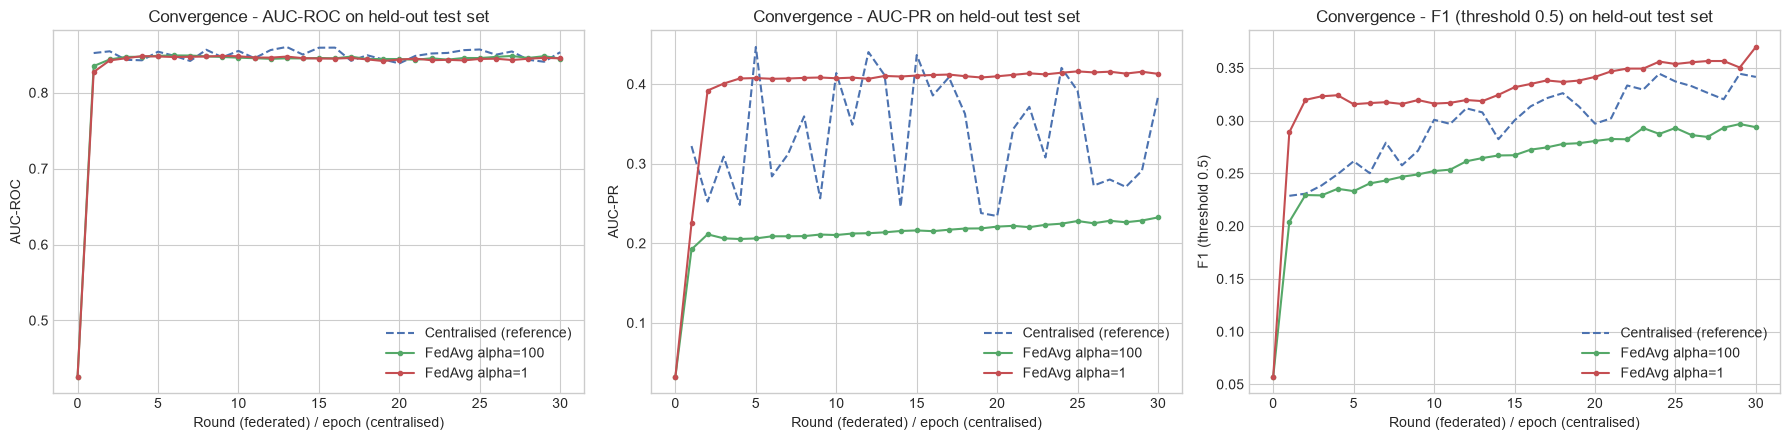

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
c_rounds = [h["round"] for h in central_history]

for ax, key, label in [(axes[0], "auc_roc", "AUC-ROC"),
                       (axes[1], "auc_pr", "AUC-PR"),
                       (axes[2], "f1", "F1 (threshold 0.5)")]:
    ax.plot(c_rounds, [h[key] for h in central_history],
            ls="--", color="#4C72B0", label="Centralised (reference)")
    for a, colour in zip(ALPHAS, ["#55A868", "#C44E52"]):
        hist = fed_histories[a]
        ax.plot([h["round"] for h in hist], [h[key] for h in hist],
                marker="o", ms=3, color=colour, label=f"FedAvg alpha={a:g}")
    ax.set_title(f"Convergence - {label} on held-out test set")
    ax.set_xlabel("Round (federated) / epoch (centralised)")
    ax.set_ylabel(label)
    ax.legend()

plt.tight_layout()
plt.show()

In [25]:
# Values are read from the history dicts rather than via summary.loc[i, col]:
# pandas-stubs types a .loc[int, str] lookup as a wide scalar union that includes
# np.timedelta64, so arithmetic on two such values resolves through
# timedelta64.__rsub__ and trips a deprecation warning in the type checker.
cen = central_final["auc_roc"]
a_iid = fed_histories[ALPHAS[0]][-1]["auc_roc"]
a_noniid = fed_histories[ALPHAS[1]][-1]["auc_roc"]

print(f"Centralised  AUC-ROC: {cen:.4f}")
print(f"FedAvg a={ALPHAS[0]:g}  AUC-ROC: {a_iid:.4f}")
print(f"FedAvg a={ALPHAS[1]:g}    AUC-ROC: {a_noniid:.4f}")
print(f"\nheterogeneity cost (alpha={ALPHAS[0]:g} -> alpha={ALPHAS[1]:g}): "
      f"{a_iid - a_noniid:+.4f} AUC-ROC")
print(f"federation cost (centralised -> alpha={ALPHAS[0]:g}):   "
      f"{a_iid - cen:+.4f} AUC-ROC")
print(f"\nordering centralised >= alpha={ALPHAS[0]:g} >= alpha={ALPHAS[1]:g} holds: "
      f"{cen >= a_iid >= a_noniid}")

Centralised  AUC-ROC: 0.8533
FedAvg a=100  AUC-ROC: 0.8449
FedAvg a=1    AUC-ROC: 0.8452

heterogeneity cost (alpha=100 -> alpha=1): -0.0003 AUC-ROC
federation cost (centralised -> alpha=100):   -0.0084 AUC-ROC

ordering centralised >= alpha=100 >= alpha=1 holds: False


## 9. Known simplifications

This is a **baseline**, deliberately unprotected. Each item below is a gap that the AQ-FL implementation closes or must explicitly justify.

- **Global preprocessing.** Imputers, scaler, and encoder are fit on the pooled training portion (Section 1), which presumes central access to all clients' feature distributions — the very thing FL avoids. Accepted here to isolate the heterogeneity effect; a federated or per-client preprocessing scheme is required before any deployment claim.
- **No secure aggregation.** Client updates are averaged in the clear. There is no secret sharing, no masking, and no post-quantum key exchange — these are the AQ-FL contribution and are measured *against* this baseline.
- **No Byzantine clients.** Every client is honest and returns a genuine update. Robust aggregation (`Krum`, `Bulyan`, or the AQ-FL custom `aggregate_fit`) is untested here because there is no adversary to filter.
- **No privacy accounting.** No differential privacy, no gradient clipping, no privacy budget. Gradient-inversion risk against the shared updates is not assessed.
- **Single seed per condition.** Each condition is one run at `SEED = 42`; the Dirichlet draw itself is stochastic, so the gap between conditions carries run-to-run variance that a single seed cannot quantify. Multiple seeds are needed before reporting any gap as a point estimate.
- **One architecture, no tuning.** Layer widths, dropout, learning rate, and `LOCAL_EPOCHS = 1` are fixed a priori, not tuned. The centralised reference is therefore an upper bound *for this configuration*, not the best achievable centralised model.
- **Temporal drift unmodelled.** Fraud prevalence differs between the training and holdout windows (Section 2). No drift correction or recalibration is applied.
- **`V1–V339` median-imputed.** The audit established that this block's ~86% missingness is *structured* (populated only for the sub-population each feature was engineered for). Median imputation discards that structure; a missingness-indicator scheme is the documented follow-up.